Load in literature and experimental data

In [2]:
import pandas as pd

DROP = [
    "rxn_id",
    "ligand_1_cas",
    "ligand_1_smiles",
    "conformer",
    "product_1_product_2_ddg_kcal",
]

literature = pd.read_csv("../../data/dft-descriptors/HF-Literature.tsv", sep="\t")

X_lit, y_lit, labels = (
    literature.drop(columns=DROP, axis=1),
    literature["product_1_product_2_ddg_kcal"],
    literature["ligand_1_cas"],
)

experimental = pd.read_csv("../../data/dft-descriptors/HF-Experimental.tsv", sep="\t")
X_exp, y_exp = (
    experimental.drop(columns=DROP, axis=1),
    experimental["product_1_product_2_ddg_kcal"],
)

Train the model and evaluate it using leave-one-catalyst-out cross-validation


In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

scoring = {
    "neg_rmse": "neg_root_mean_squared_error",
    "neg_mae": "neg_mean_absolute_error",
}

cv_preds = []
exp_preds = []

model = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("model", RandomForestRegressor(random_state=42)),
    ]
)

cv_pred = cross_val_predict(
    model,
    X_lit.values,
    y_lit.values,
    cv=LeaveOneGroupOut(),
    groups=labels,
    n_jobs=22,
)

model.fit(X_lit.values, y_lit.values)

cv_preds.append(cv_pred)
exp_preds.append(model.predict(X_exp.values))

Average the predictions for each catalyst across the conformers

In [4]:
import numpy as np

# Get predictions
lit_pred = np.array(cv_preds).mean(axis=0)
exp_pred = np.array(exp_preds).mean(axis=0)

# Add predictions to the dataframes
literature["prediction"] = lit_pred
experimental["prediction"] = exp_pred

# Get average values for each reaction
y_lit_avg = literature.groupby("rxn_id")["product_1_product_2_ddg_kcal"].mean()
lit_pred = literature.groupby("rxn_id")["prediction"].mean()

y_exp_avg = experimental.groupby("rxn_id")["product_1_product_2_ddg_kcal"].mean()
exp_pred = experimental.groupby("rxn_id")["prediction"].mean()

literature.drop(columns="prediction", inplace=True)
experimental.drop(columns="prediction", inplace=True)

Visualize the results

Lit R^2: 0.52, RMSE: 0.88, MAE: 0.64
Exp R^2: 0.41, RMSE: 0.74, MAE: 0.61


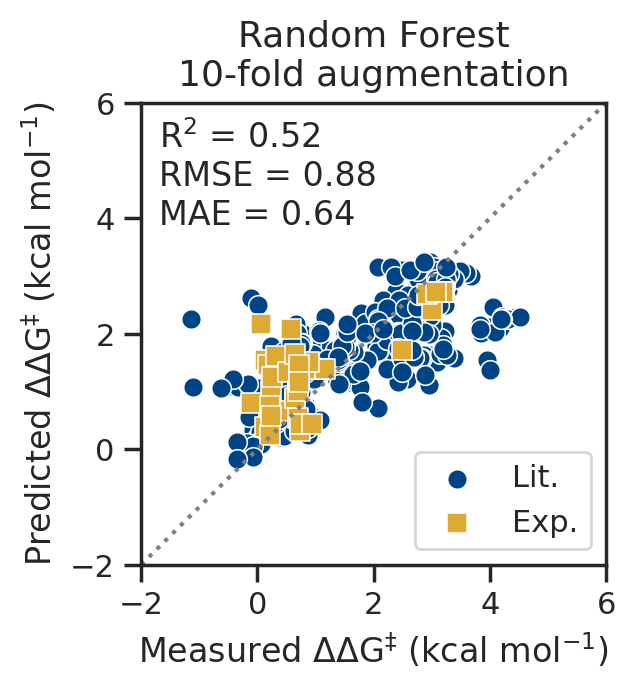

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

# Define colors and theme
colors = ["#004488", "#DDAA33", "#BB5566", "#000000"]
color = sns.color_palette(colors)
plt.rcParams.update({"figure.figsize": (3, 3)})
sns.set(rc={"figure.dpi": 200})
sns.set_theme(style="ticks", palette=color)
plt.tight_layout()

lit_r2 = r2_score(y_lit_avg, lit_pred)
exp_r2 = r2_score(y_exp_avg, exp_pred)

lit_rmse = root_mean_squared_error(y_lit_avg, lit_pred)
lit_mae = mean_absolute_error(y_lit_avg, lit_pred)

exp_rmse = root_mean_squared_error(y_exp_avg, exp_pred)
exp_mae = mean_absolute_error(y_exp_avg, exp_pred)

ax = sns.scatterplot(x=y_lit_avg, y=lit_pred, label="Lit.", alpha=1, s=50, legend=False)
sns.scatterplot(x=y_exp_avg, y=exp_pred, label="Exp.", ax=ax, alpha=1, marker="s", s=50)

ax.set(
    xlabel=r"Measured $\Delta\Delta$G$^\ddag$ (kcal mol$^{-1}$)",
    ylabel=r"Predicted $\Delta\Delta$G$^\ddag$ (kcal mol$^{-1}$)",
)
ax.set_xlim(-2, 6)
ax.set_ylim(-2, 6)

ax.plot(
    [0, 1],
    [0, 1],
    ":",
    color="grey",
    transform=ax.transAxes,
)
ax.set_title("Random Forest\n10-fold augmentation", fontsize=13)

ax.text(
    -1.7,
    5.7,
    f"R$^2$ = {lit_r2:0.2f}\nRMSE = {lit_rmse:0.2f}\nMAE = {lit_mae:0.2f}",
    fontsize=12,
    horizontalalignment="left",
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.9),
)

print(f"Lit R^2: {lit_r2:0.2f}, RMSE: {lit_rmse:0.2f}, MAE: {lit_mae:0.2f}")
print(f"Exp R^2: {exp_r2:0.2f}, RMSE: {exp_rmse:0.2f}, MAE: {exp_mae:0.2f}")